In [2]:
#| tbl-cap: "Nombre de fichiers du catalogue CWRU par source et type de défaut."
#| label: tbl-catalogue
#Bloc 1 : remplace les deux anciens blocs de chargement
#Ce que fait chaque partie
#1.1 recopie les tableaux des quatre pages du site. Les numéros ont été vérifiés aujourd’hui sur les pages elles-mêmes, et None correspond aux astérisques (données non disponibles).
#1.2 transforme ces tableaux en une table, le catalogue, avec une ligne par fichier et un nom qui résume tout. Par exemple, 12kDE_OR021at3_L2 se lit : 12 kHz, défaut côté entraînement, bague extérieure, 0,021", position 3 h, charge 2 HP.
#1.3 définit charger(nom). Elle télécharge le fichier la première fois, puis le relit en local. Elle choisit la bonne variable quand un fichier en contient deux, et prend la vitesse nominale si la vitesse mesurée manque. Ce sont les deux défauts du code précédent.

#Résultat attendu : 161 fichiers au catalogue, puis un tableau de synthèse :
import io
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as sci
from scipy.io import loadmat
from scipy.signal import hilbert
from scipy.stats import kurtosis
from scipy.fftpack import fft, fftfreq
from pathlib import Path
from IPython.display import Markdown

# ------------------------------------------------------------------
# 1.1 Les numéros de fichiers du site, page par page
#     clé = (défaut, diamètre en millièmes de pouce)
#     valeur = numéros pour les charges 0, 1, 2, 3 HP (None = absent)
# ------------------------------------------------------------------
NORMAL = [97, 98, 99, 100]

PAGES = {
    "12kDE": (12000, {
        ("IR", 7): [105, 106, 107, 108],      ("B", 7): [118, 119, 120, 121],
        ("OR@6", 7): [130, 131, 132, 133],    ("OR@3", 7): [144, 145, 146, 147],
        ("OR@12", 7): [156, 158, 159, 160],
        ("IR", 14): [169, 170, 171, 172],     ("B", 14): [185, 186, 187, 188],
        ("OR@6", 14): [197, 198, 199, 200],
        ("IR", 21): [209, 210, 211, 212],     ("B", 21): [222, 223, 224, 225],
        ("OR@6", 21): [234, 235, 236, 237],   ("OR@3", 21): [246, 247, 248, 249],
        ("OR@12", 21): [258, 259, 260, 261],
        ("IR", 28): [3001, 3002, 3003, 3004], ("B", 28): [3005, 3006, 3007, 3008],
    }),
    "48kDE": (48000, {
        ("IR", 7): [109, 110, 111, 112],      ("B", 7): [122, 123, 124, 125],
        ("OR@6", 7): [135, 136, 137, 138],    ("OR@3", 7): [148, 149, 150, 151],
        ("OR@12", 7): [161, 162, 163, 164],
        ("IR", 14): [174, 175, 176, 177],     ("B", 14): [189, 190, 191, 192],
        ("OR@6", 14): [201, 202, 203, 204],
        ("IR", 21): [213, 214, 215, 217],     ("B", 21): [226, 227, 228, 229],
        ("OR@6", 21): [238, 239, 240, 241],   ("OR@3", 21): [250, 251, 252, 253],
        ("OR@12", 21): [262, 263, 264, 265],
    }),
    "12kFE": (12000, {
        ("IR", 7): [278, 279, 280, 281],      ("B", 7): [282, 283, 284, 285],
        ("OR@6", 7): [294, 295, 296, 297],    ("OR@3", 7): [298, 299, 300, 301],
        ("OR@12", 7): [302, 305, 306, 307],
        ("IR", 14): [274, 275, 276, 277],     ("B", 14): [286, 287, 288, 289],
        ("OR@6", 14): [313, None, None, None], ("OR@3", 14): [310, 309, 311, 312],
        ("IR", 21): [270, 271, 272, 273],     ("B", 21): [290, 291, 292, 293],
        ("OR@6", 21): [315, None, None, None], ("OR@3", 21): [None, 316, 317, 318],
    }),
}

RPM_NOMINAL = {0: 1797, 1: 1772, 2: 1750, 3: 1730}

# ------------------------------------------------------------------
# 1.2 Le catalogue : une ligne par fichier, avec un nom lisible
#     ex. 'Normal_L0', '12kDE_IR007_L0', '12kDE_OR021at3_L2', '48kDE_B014_L1'
# ------------------------------------------------------------------
lignes = []
for charge, num in enumerate(NORMAL):
    lignes.append({"nom": f"Normal_L{charge}", "numero": num, "source": "Normal",
                   "fs": 12000, "defaut": "Sain", "position_OR": None,
                   "diametre_mils": 0, "charge_hp": charge})

for source, (fs, table) in PAGES.items():
    for (defaut, diametre), numeros in table.items():
        localisation, _, position = defaut.partition("@")
        for charge, num in enumerate(numeros):
            if num is None:
                continue
            nom = f"{source}_{localisation}{diametre:03d}" + (f"at{position}" if position else "") + f"_L{charge}"
            lignes.append({"nom": nom, "numero": num, "source": source, "fs": fs,
                           "defaut": localisation, "position_OR": position or None,
                           "diametre_mils": diametre, "charge_hp": charge})

catalogue = pd.DataFrame(lignes).set_index("nom")
catalogue["rpm_nominal"] = catalogue["charge_hp"].map(RPM_NOMINAL)

# ------------------------------------------------------------------
# 1.3 Lecture d'un fichier depuis le site (copie locale sous un nom lisible)
# ------------------------------------------------------------------
URL_CWRU = "https://engineering.case.edu/sites/default/files/"

def trouver_racine(repo="BDS_Fault_Detection", depart=None):
    """Remonte l'arborescence depuis le code en exécution jusqu'au dossier du dépôt et renvoie son chemin absolu."""
    dossier = Path(depart) if depart is not None else Path.cwd()
    dossier = dossier.resolve()
    if dossier.is_file():
        dossier = dossier.parent
    for parent in (dossier, *dossier.parents):
        if repo in parent.name:
            return parent
    raise FileNotFoundError(f"Racine '{repo}' introuvable depuis {dossier}")



RACINE = trouver_racine()
CACHE_path = RACINE / "data" / "cwru_cache"
FEATURES_path = RACINE / "data" / "features"



def charger(nom):
    """Renvoie {'DE', 'FE', 'BA', 'fs', 'rpm'} pour un fichier du catalogue
    (ex. '12kDE_IR007_L0')."""
    info = catalogue.loc[nom]
    numero = int(info["numero"])
    chemin = CACHE_path / f"{nom}__{numero}.mat"            # ex. 12kDE_IR007_L0__105.mat

    if not chemin.exists():                            # 1re fois : téléchargement depuis le site
        CACHE_path.mkdir(parents=True, exist_ok=True)
        with urllib.request.urlopen(URL_CWRU + f"{numero}.mat") as reponse:
            chemin.write_bytes(reponse.read())
    mat = loadmat(chemin)

    def choisir(suffixe):                              # privilégie la variable du bon numéro
        cles = [k for k in mat if k.endswith(suffixe)]
        bonne = [k for k in cles if k.startswith(f"X{numero:03d}")]
        return (bonne or cles or [None])[0]

    signaux = {"fs": int(info["fs"])}
    for canal in ["DE", "FE", "BA"]:
        cle = choisir(f"_{canal}_time")
        signaux[canal] = None if cle is None else np.ravel(mat[cle])
    cle_rpm = choisir("RPM")
    signaux["rpm"] = float(np.squeeze(mat[cle_rpm])) if cle_rpm else float(info["rpm_nominal"])
    return signaux



tab = catalogue.groupby(["source", "defaut"]).size().unstack(fill_value=0)
tab = tab[["Sain", "IR", "B", "OR"]].reindex(["Normal", "12kDE", "48kDE", "12kFE"])
tab = tab.reset_index().rename(columns={"source": "Source", "IR": "Bague int. (IR)",
                                        "B": "Bille (B)", "OR": "Bague ext. (OR)"})
Markdown(tab.to_markdown(index=False))



| Source   |   Sain |   Bague int. (IR) |   Bille (B) |   Bague ext. (OR) |
|:---------|-------:|------------------:|------------:|------------------:|
| Normal   |      4 |                 0 |           0 |                 0 |
| 12kDE    |      0 |                16 |          16 |                28 |
| 48kDE    |      0 |                12 |          12 |                28 |
| 12kFE    |      0 |                12 |          12 |                21 |

In [3]:
####################################################################################################################################################
#| label: selection
#| code-summary: "Sélection des 40 fichiers"
#| tbl-cap: "Nombre de fichiers sélectionnés par localisation et diamètre du défaut."
est_sain   = catalogue["source"] == "Normal"
est_12kDE  = catalogue["source"] == "12kDE"
bon_defaut = catalogue["defaut"].isin(["IR", "B"]) | (catalogue["position_OR"] == "6")
bon_diam   = catalogue["diametre_mils"].isin([7, 14, 21])

selection = catalogue[est_sain | (est_12kDE & bon_defaut & bon_diam)]
selection.groupby(["defaut", "diametre_mils"]).size().unstack(fill_value=0)


diametre_mils,0,7,14,21
defaut,,,,
B,0,4,4,4
IR,0,4,4,4
OR,0,4,4,4
Sain,4,0,0,0


In [10]:
selection.head(10)

,numero,source,fs,defaut,position_OR,diametre_mils,charge_hp,rpm_nominal
nom,,,,,,,,
Normal_L0,97,Normal,12000,Sain,NaN,0,0,1797
Normal_L1,98,Normal,12000,Sain,NaN,0,1,1772
Normal_L2,99,Normal,12000,Sain,NaN,0,2,1750
Normal_L3,100,Normal,12000,Sain,NaN,0,3,1730
12kDE_IR007_L0,105,12kDE,12000,IR,NaN,7,0,1797
12kDE_IR007_L1,106,12kDE,12000,IR,NaN,7,1,1772
12kDE_IR007_L2,107,12kDE,12000,IR,NaN,7,2,1750
12kDE_IR007_L3,108,12kDE,12000,IR,NaN,7,3,1730
12kDE_B007_L0,118,12kDE,12000,B,NaN,7,0,1797


In [5]:
#| label: table-indicateurs
#| code-summary: "Calcul des indicateurs par fenêtre"
#| tbl-cap: "Nombre de fenêtres de 0.2s après découpage du signal"
def indicateurs(x):
    rms = np.sqrt(np.mean(x**2))
    pic = np.max(np.abs(x))
    return {"RMS": rms, "Pic": pic, "Crete": pic / rms,
            "Kurtosis": kurtosis(x, fisher=False)}

DUREE_FENETRE = 0.2      # secondes

lignes = []
for nom, info in selection.iterrows():
    s = charger(nom)                                   # téléchargement la 1re fois
    x, fs = s["DE"], s["fs"]
    taille = int(DUREE_FENETRE * fs)
    for i in range(len(x) // taille):
        res = {"fichier": nom, "fenetre": i, "rpm": s["rpm"], **info.to_dict()}
        res.update(indicateurs(x[i*taille:(i+1)*taille]))
        lignes.append(res)

table = pd.DataFrame(lignes)
table["classe"] = np.where(table["defaut"] == "Sain", "Sain",
                           table["defaut"] + table["diametre_mils"].astype(str).str.zfill(3))

Path(FEATURES_path).mkdir(parents=True, exist_ok=True)
table.to_csv(FEATURES_path / "table_indicateurs.csv", index=False)

#print(f"{len(table)} fenêtres issues de {table['fichier'].nunique()} fichiers")
table.groupby(["classe", "charge_hp"]).size().unstack()
table

,fichier,fenetre,rpm,numero,source,fs,defaut,position_OR,diametre_mils,charge_hp,rpm_nominal,RMS,Pic,Crete,Kurtosis,classe
0,Normal_L0,0,1796.0,97,Normal,12000,Sain,NaN,0,0,1797,0.073348,0.272869,3.720207,2.859637,Sain
1,Normal_L0,1,1796.0,97,Normal,12000,Sain,NaN,0,0,1797,0.078434,0.226765,2.891156,2.863790,Sain
2,Normal_L0,2,1796.0,97,Normal,12000,Sain,NaN,0,0,1797,0.073608,0.249295,3.386784,2.794364,Sain
3,Normal_L0,3,1796.0,97,Normal,12000,Sain,NaN,0,0,1797,0.073188,0.247418,3.380577,2.935528,Sain
4,Normal_L0,4,1796.0,97,Normal,12000,Sain,NaN,0,0,1797,0.071653,0.224679,3.135669,2.833588,Sain
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2506,12kDE_OR021at6_L3,45,1721.0,237,12kDE,12000,OR,6,21,3,1730,0.578494,5.779442,9.990501,29.266426,OR021
2507,12kDE_OR021at6_L3,46,1721.0,237,12kDE,12000,OR,6,21,3,1730,0.625354,5.742082,9.182123,25.750308,OR021
2508,12kDE_OR021at6_L3,47,1721.0,237,12kDE,12000,OR,6,21,3,1730,0.605118,5.104118,8.434920,21.318378,OR021
2509,12kDE_OR021at6_L3,48,1721.0,237,12kDE,12000,OR,6,21,3,1730,0.681556,5.662489,8.308175,22.605605,OR021


In [ ]:
INDICATEURS = ["RMS", "Pic", "Crete", "Kurtosis"]
ORDRE = ["Sain", "IR007", "IR014", "IR021", "B007", "B014", "B021",
         "OR007", "OR014", "OR021"]


def spectre_fft(x, fs):
    """Spectre d'amplitude : renvoie (fréquences, amplitudes)."""
    n = len(x)
    freqs = fftfreq(n, d=1 / fs)[: n // 2]
    amp = np.abs(fft(x - np.mean(x)))[: n // 2] * 2 / n # ajout de "- np.mean(x)" pour supprimer la composante continue du signal
    return freqs, amp

fs = 12_000


COEFF_FREQ = {  # coefficients × fréquence de rotation, source CWRU
    "DE": {"BPFI": 5.4152, "BPFO": 3.5848, "BSF": 4.7135, "FTF": 0.39828},
    "FE": {"BPFI": 4.9469, "BPFO": 3.0530, "BSF": 3.9874, "FTF": 0.3817},
}
RPM = defaut["rpm"] # vitesse du fichier si présente, sinon nominale du catalogue

def freqs_caracteristiques(roulement, rpm=RPM):
    """Fréquences caractéristiques (Hz) du roulement 'DE' ou 'FE'."""
    f_rot = rpm / 60
    return {nom: coef * f_rot for nom, coef in COEFF_FREQ[roulement].items()}




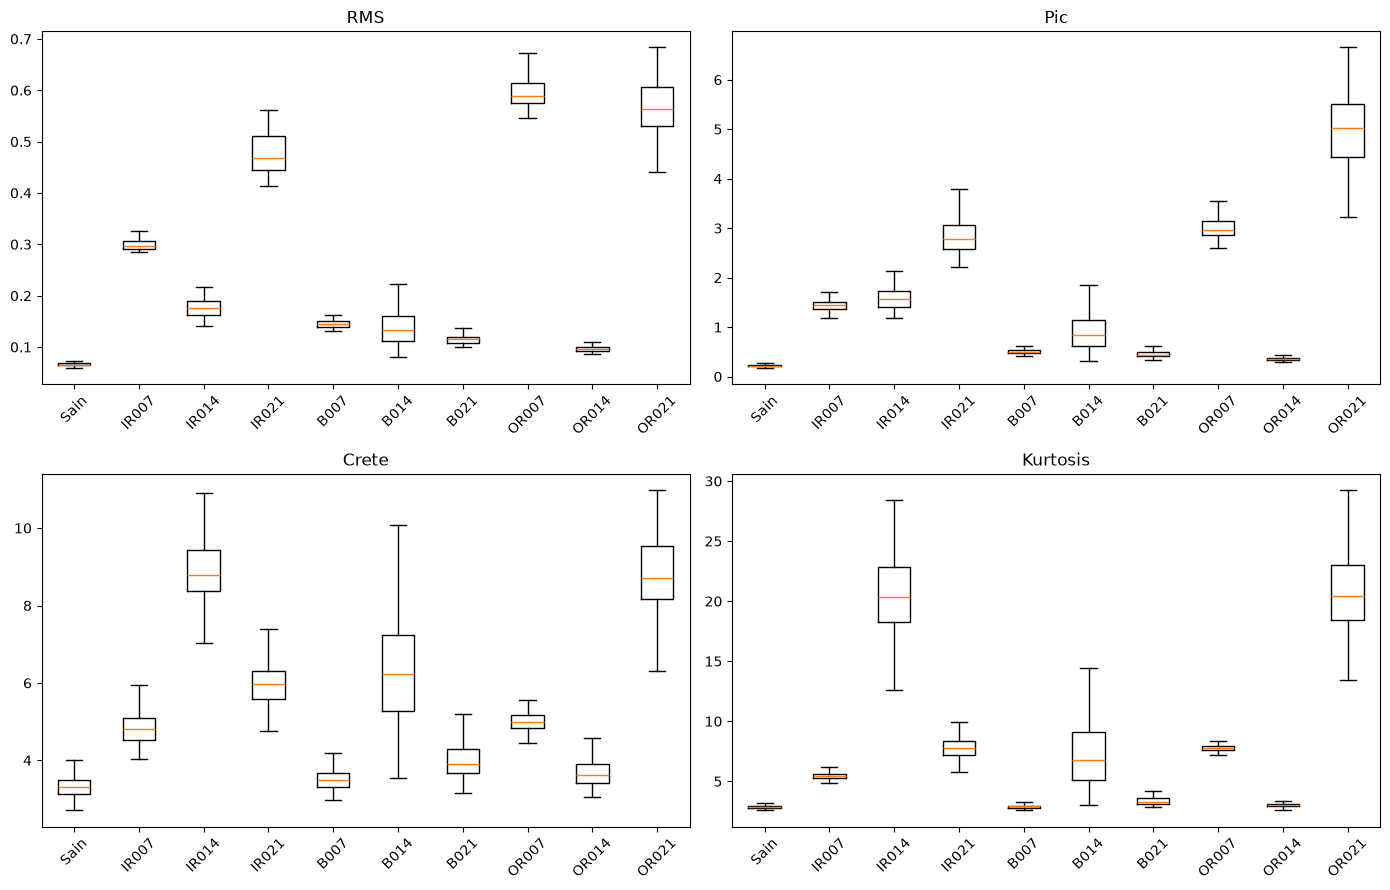

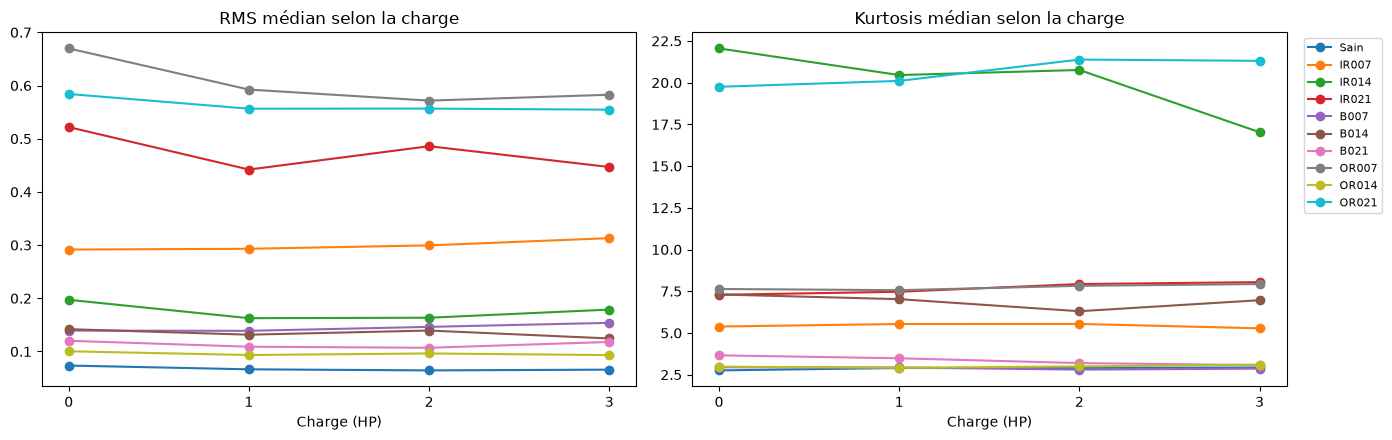

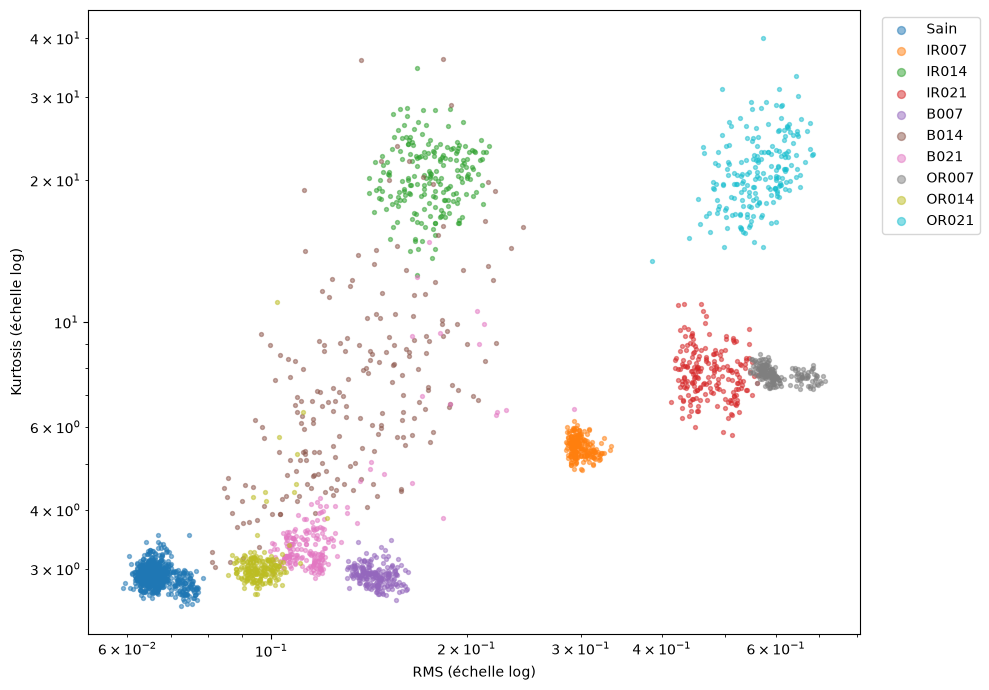

'\n\n#| label: fig-spectre\n#| fig-cap: "Décomposition d\'un signal synthétique : composantes temporelles (gauche) et spectrales (droite)."\n# Définitions fonctions\ndef spectre_fft(x, fs):\n    """Spectre d\'amplitude : renvoie (fréquences, amplitudes)."""\n    n = len(x)\n    freqs = fftfreq(n, d=1 / fs)[: n // 2]\n    amp = np.abs(fft(x - np.mean(x)))[: n // 2] * 2 / n # ajout de "- np.mean(x)" pour supprimer la composante continue du signal\n    return freqs, amp\n\nfs = 12_000\nt = np.arange(0, 1, 1 / fs)\nx30hz = 1.0 * np.sin(2 * np.pi * 30 * t)      # "rotation" à 30 Hz\nx162hz = 0.5 * np.sin(2 * np.pi * 162 * t)    # "défaut" à 162 Hz\nxbruit = 0.3 * np.random.randn(len(t))        # bruit \nxtot = x30hz + x162hz + xbruit\n\n# --- Calcul des spectres (une seule fois par composante) ---\nf_30hz, a30 = spectre_fft(x30hz, fs)\nf_162hz, a162 = spectre_fft(x162hz, fs)\nf_bruit, a_bruit = spectre_fft(xbruit, fs)\nf_tot, a_tot = spectre_fft(xtot, fs)\n\nfig, axes = plt.subplots(4, 2, f

In [ ]:


#| label: fig-spectre
#| fig-cap: "Décomposition d'un signal synthétique : composantes temporelles (gauche) et spectrales (droite)."
# Définitions fonctions

# --- Fichiers étudiés : baseline saine et défaut bague intérieure, 0 HP ---
NOM_SAIN   = "Normal_L0"
NOM_DEFAUT = "12kDE_IR007_L0"

sain   = charger(NOM_SAIN)
defaut = charger(NOM_DEFAUT)

STYLES = {
    "condition": {"Sain": "#149C07", "Défaut": "#C82909"},
    "canal":     {"DE": "-",        "FE": "--"},
}

STYLES_RAIES = {  # fréquences caractéristiques
    "BPFI": ("purple", "-"),
    "BPFO": ("blue",   "--"),
    "BSF":  ("orange", "-."),
    "FTF":  ("green",  ":"),
}




#|  tbl-cap: "Résumé des signaux, durées calculées avec le fs annoncé par le catalogue."

SIGNAUX = {  # nom: (signaux, canal, condition)
    "Sain — moteur (DE)":        (sain,   "DE", "Sain"),
    "Sain — ventilateur (FE)":   (sain,   "FE", "Sain"),
    "Défaut — moteur (DE)":      (defaut, "DE", "Défaut"),
    "Défaut — ventilateur (FE)": (defaut, "FE", "Défaut"),
}

resume = pd.DataFrame([
    {"Condition": nom,
     "Nombre de points": len(s[canal]),
     "fs (Hz)": s["fs"],
     #"Durée (s)": round(len(s[canal]) / s["fs"], 2),
     #"NaN": int(np.sum(~np.isfinite(s[canal])))}
     "NaN": int(np.sum(pd.isna(s[canal])))}
    for nom, (s, canal, _) in SIGNAUX.items()
])
resume




#|  tbl-cap: "Contrôle du fs sur base de fréquence de rotation moteur."
def spectre_fft(x, fs):
    """Spectre d'amplitude : renvoie (fréquences, amplitudes)."""
    
    n = len(x)
    freqs = fftfreq(n, d=1 / fs)[: n // 2]
    # amp = np.abs(fft(x))[: n // 2] * 2 / n
    # ajout de "- np.mean(x)" pour supprimer la composante continue du signal
    amp = np.abs(fft(x - np.mean(x)))[: n // 2] * 2 / n
    return freqs, amp

x = sain["DE"]  # signal du capteur DE (Drive End)
fig, axes = plt.subplots(3, 1, figsize=(12, 9))
for ax, fs in zip(axes, [48000, 24000, 12000]):
    f, a = spectre_fft(x, fs)
    ax.plot(f, a)
    ax.set_xlim(0, 150)
    ax.set_ylim(0, 0.015)
    ax.axvline(1797/60, color="red", ls="--", label="rotation moteur attendue ≈ 30 Hz")
    ax.set_title(f"Signal sain, en supposant fs = {fs} Hz")
    ax.legend()
axes[1].set_xlabel("Fréquence (Hz)")
plt.tight_layout(); plt.show()





pd.DataFrame({
    "vitesse de rotation": [f"{RPM:.0f} tr/min"] * len(COEFF_FREQ["DE"]),
    "coefficient": pd.Series(COEFF_FREQ["DE"]),
    "f. caractéristique (DE)": pd.Series(freqs_caracteristiques("DE")).round(2).astype(str) + " Hz",
}).round(4)







#| fig-cap: "0,1 seconde de signal ; vert = sain, rouge = défaut ; trait plein = Drive End, tirets = Fan End."

def tracer_temps(x, fs, ax, condition, canal, titre):
    n = int(0.1 * fs)
    ax.plot(np.arange(n) / fs, x[:n],
            color=STYLES["condition"][condition],
            ls=STYLES["canal"][canal], lw=0.7)
    ax.set_title(titre, loc="left")
    ax.set_xlabel("Temps (s)")
    ax.set_ylabel("Amplitude")
    ax.grid(alpha=0.3)

fig, axes = plt.subplots(2, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, (nom, (s, canal, cond)) in zip(axes.flat, SIGNAUX.items()):
    tracer_temps(s[canal], s["fs"], ax, cond, canal, nom)
plt.tight_layout(); plt.show()





#| fig-cap: "Zoom sur 30 ms du signal défectueux ; les repères sont espacés de la période BPFI théorique."

BPFI_DE = freqs_caracteristiques("DE")["BPFI"]
fs = defaut["fs"]

x = defaut["DE"]
n = int(0.03 * fs)
t = np.arange(n) / fs
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(t, x[:n], color="red", ls="-", lw=0.8, label="Signal")
ax.vlines(np.arange(0, t[-1], 1 / BPFI_DE), *ax.get_ylim(),
          colors="crimson", ls=":", lw=1,
          label=f"Période BPFI ≈ {BPFI_DE:.0f} Hz")
ax.set_title("Défaut bague intérieure — repérage des chocs", loc="left")
ax.set_xlabel("Temps (s)"); ax.set_ylabel("Accélération (g)")
ax.legend(loc="upper right", fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()





#| fig-cap: "Spectres d'amplitude FFT : le défaut ajoute de l'énergie haute fréquence."

def tracer_fft(ax, x, fs, condition, canal, titre,
               roulement=None, x_max=None):
    freqs, amp = spectre_fft(x, fs)
    ax.plot(freqs, amp, color=STYLES["condition"][condition],
            ls=STYLES["canal"][canal], lw=0.5)
    ax.set_title(titre, loc="left")
    ax.set_xlim(0, x_max if x_max else fs / 2)
    ax.set_xlabel("Fréquence (Hz)")
    ax.grid(alpha=0.3)
    if roulement:  # raies caractéristiques + harmoniques 2x, 3x
        for nom, val in freqs_caracteristiques(roulement).items():
            couleur, ls = STYLES_RAIES[nom]
            ax.axvline(val, color=couleur, ls=ls, lw=1.8, alpha=0.4,
                       label=f"{nom} = {val:.1f} Hz")
            for k in range(2, 4):
                if k * val < (x_max or fs / 2):
                    ax.axvline(k * val, color=couleur, ls=ls,
                               lw=0.8, alpha=0.2)
        ax.legend(loc="upper right", fontsize=8, framealpha=0.7)

fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharey=True)
for colonne, canal in enumerate(("DE", "FE")):
    for ligne, condition in enumerate(("Sain", "Défaut")):
        nom = [n for n in SIGNAUX
               if n.endswith(f"({canal})") and n.startswith(condition)][0]
        s, can, cond = SIGNAUX[nom][0], canal, condition
        tracer_fft(axes[ligne, colonne], s[canal], s["fs"], cond, can, nom)
        if colonne == 0:
            axes[ligne, colonne].set_ylabel("Amplitude")
plt.tight_layout(); plt.show()




#| fig-cap: "FFT basse fréquence du signal défectueux avec raies caractéristiques (fondamentales et harmoniques)."

fs = defaut["fs"]

# Fenêtre d'affichage : jusqu'à 3,5 × la raie BPFI la plus haute
X_MAX = max(freqs_caracteristiques(r)["BPFI"] for r in ("DE", "FE")) * 3.5

# Chaque spectre n'est calculé qu'une seule fois
SPECTRES_DEFAUT = {canal: spectre_fft(defaut[canal], fs)
                   for canal in ("DE", "FE")}
Y_MAX = max(amp[(freqs >= 0) & (freqs <= X_MAX)].max()
            for freqs, amp in SPECTRES_DEFAUT.values())

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharey=True)
for ax, (canal, (freqs, amp)) in zip(axes, SPECTRES_DEFAUT.items()):
    tracer_fft(ax, defaut[canal], fs, "Défaut", canal, f"Défaut — {canal}",
               roulement=canal, x_max=X_MAX)
    ax.set_ylim(0, Y_MAX * 1.05)
    ax.set_ylabel("Amplitude")
plt.tight_layout(); plt.show()





#| fig-cap: "Les étapes de l'analyse d'enveloppe sur le signal défectueux (côté moteur)."

BANDE_RESONANCE = (1000, 4000)  # bande de résonance isolée (Hz)
N_FFT = 2 ** 14

def filtrer_passe_bande(x, fs, bande=BANDE_RESONANCE):
    sos = sci.butter(4, [bande[0] / (fs / 2), bande[1] / (fs / 2)],
                     btype="bandpass", output="sos")
    return sci.sosfiltfilt(sos, x)     # zero-phase : chocs non décalés

def extraire_enveloppe(x):
    env = np.abs(hilbert(x))
    return env - np.mean(env)          # retire le pic à 0 Hz

def spectre_enveloppe(x, fs, bande=BANDE_RESONANCE, n_fft=N_FFT):
    """Chaîne complète : passe-bande + Hilbert + FFT."""
    env = extraire_enveloppe(filtrer_passe_bande(x, fs, bande))
    fenetre = np.hanning(len(env))
    freqs = np.fft.rfftfreq(n_fft, d=1 / fs)
    amp = np.abs(np.fft.rfft(env * fenetre, n=n_fft)) / np.sum(fenetre) * 2
    return freqs, amp

fs = defaut["fs"]
x = defaut["DE"]
x_filtre = filtrer_passe_bande(x, fs)
enveloppe = extraire_enveloppe(x_filtre)
t = np.arange(len(x)) / fs

fig, axes = plt.subplots(4, 1, figsize=(12, 11))
vues = [
    (f"1. Signal brut — chocs noyés dans les résonances (Défaut — DE)", x, "red", "-"),
    (f"2. Après filtre passe-bande {BANDE_RESONANCE[0]}–{BANDE_RESONANCE[1]} Hz",
     x_filtre, "tab:blue", "-"),
    ("3. Enveloppe (Hilbert) — le rythme des chocs apparaît",
     enveloppe, "tab:green", "-"),
]
for ax, (titre, sig, couleur, ls) in zip(axes, vues):
    n = int(0.05 * fs)
    ax.plot(t[:n], sig[:n], color=couleur, ls=ls, lw=0.8)
    ax.set_title(titre, loc="left")
    ax.set_ylabel("Amplitude")
    ax.grid(alpha=0.3)

freqs_env, amp_env = spectre_enveloppe(x, fs)
ax = axes[3]
ax.plot(freqs_env, amp_env, color="tab:red", lw=0.8)
ax.set_title("4. FFT de l'enveloppe — raies caractéristiques nettes", loc="left")
ax.set_ylabel("Amplitude d'enveloppe")
ax.set_xlabel("Fréquence (Hz)")
ax.set_xlim(0, X_MAX)
for nom, val in freqs_caracteristiques("DE").items():
    if nom != "BPFI":
        continue
    couleur, ls = STYLES_RAIES[nom]
    ax.axvline(val, color=couleur, ls=ls, lw=1.5, alpha=0.5,
               label=f"{nom} = {val:.1f} Hz")

    for k in range(2, 4):              # harmoniques 2x et 3x
        if k * val < X_MAX:
            ax.axvline(k * val, color=couleur, ls=ls, lw=0.8, alpha=0.2)


ax.legend(loc="upper right", fontsize=8, framealpha=0.7)
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()






#| fig-cap: "Spectres d'enveloppe avec raies caractéristiques, pour les canaux moteur et ventilateur."

fs = defaut["fs"]

# Chaque spectre d'enveloppe n'est calculé qu'une seule fois
ENVELOPPES_DEFAUT = {canal: spectre_enveloppe(defaut[canal], fs)
                     for canal in ("DE", "FE")}
Y_MAX = max(amp[(freqs >= 0) & (freqs <= X_MAX)].max()
            for freqs, amp in ENVELOPPES_DEFAUT.values())

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharey=True)
for ax, (canal, (freqs_env, amp_env)) in zip(axes, ENVELOPPES_DEFAUT.items()):
    ax.plot(freqs_env, amp_env, color="red",
            ls=STYLES["canal"][canal], lw=0.5)
    ax.set_title(f"Défaut — {canal}  (filtre "
                 f"{BANDE_RESONANCE[0]}–{BANDE_RESONANCE[1]} Hz)", loc="left")
    ax.set_xlim(0, X_MAX)
    ax.set_ylim(0, Y_MAX * 1.05)
    for nom, val in freqs_caracteristiques(canal).items():
        couleur, ls = STYLES_RAIES[nom]
        ax.axvline(val, color=couleur, ls=ls, lw=1.8, alpha=0.5,
                   label=f"{nom} = {val:.1f} Hz")
        for k in range(2, 4):
            if k * val < X_MAX:
                ax.axvline(k * val, color=couleur, ls=ls, lw=0.8, alpha=0.2)
    ax.legend(loc="upper right", fontsize=8, framealpha=0.7)
    ax.set_ylabel("Amplitude d'enveloppe")
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("Fréquence (Hz)")
plt.tight_layout(); plt.show()

'''